# 07 – Nuclear speed around mitosis: step table

**Purpose:** Compute nuclear speeds and place them on a time axis relative to cell division,
(a) from the **reference** tracks and (b) from our **pipeline** tracks (fine-tuned Cellpose-SAM + Trackastra).
The statistics follow in `R/02_speed_around_mitosis.R`.

**Definitions**
- *Position*: centroid of the nucleus mask (µm).
- *Step*: displacement of the same cell between two consecutive observations; *speed* = step length / time (µm/h).
- *Reference tracks*: identity and lineage from the manual tracking reference (`01_GT/TRA`); position from the
  silver-truth mask containing the marker (whole nucleus → more stable centroid). If a marker lies in no mask
  or shares a mask with another marker, the marker's own centroid is used (`pos_source = "marker"`).
- *Pipeline tracks*: masks and lineage from notebook 06.
- *Division*: a mother track with exactly two daughters. Time 0 = between the mother's last and the daughters'
  first frame. The *division step* (mother's last position → daughter's first position) is assigned to time 0.
- Each step is assigned to its **nearest** division (a cell can be the daughter of one division and the mother
  of the next), within a window of ±8 h.

**Caveat:** the centroid also moves when the nucleus changes shape (chromatin condensation in mitosis), so
"speed" here means displacement of the nuclear centroid, not necessarily migration of the whole cell.

## 1. Settings

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from skimage.measure import regionprops_table

DATA = Path("../data/raw/Fluo-N2DL-HeLa")
RESULTS = Path("../results")
SEQ = "01"
PIXEL_SIZE_UM = 0.645
FRAME_H = 0.5            # 30 min between frames
WINDOW_FRAMES = 16       # ±8 h around division

## 2. Reference positions: tracking markers + silver-truth masks

In [2]:
tra_dir = DATA / f"{SEQ}_GT" / "TRA"
tra = np.stack([tifffile.imread(f) for f in sorted(tra_dir.glob("man_track*.tif"))])
st = np.stack([tifffile.imread(f) for f in sorted((DATA / f"{SEQ}_ST" / "SEG").glob("man_seg*.tif"))])
lineage_ref = pd.read_csv(tra_dir / "man_track.txt", sep=r"\s+", header=None,
                          names=["track", "begin", "end", "parent"])

rows = []
for t in range(len(tra)):
    # markers: one per cell, label = track ID
    m = regionprops_table(tra[t], properties=["label", "centroid"])
    markers = pd.DataFrame({"track": m["label"], "y_m": m["centroid-0"], "x_m": m["centroid-1"]})
    # silver-truth objects and the markers they contain (min/max of the marker image inside the object)
    s = regionprops_table(st[t], intensity_image=tra[t],
                          properties=["label", "centroid", "intensity_min", "intensity_max"])
    so = pd.DataFrame({"y_s": s["centroid-0"], "x_s": s["centroid-1"],
                       "tmax": s["intensity_max"].astype(int)})
    # count markers per object: an object is "unique" if exactly one marker ID falls into it
    ids_per_obj = [np.unique(tra[t][st[t] == lab]) for lab in s["label"]]
    so["n_markers"] = [np.count_nonzero(ids) for ids in ids_per_obj]
    uniq = so[so["n_markers"] == 1].rename(columns={"tmax": "track"})
    d = markers.merge(uniq[["track", "y_s", "x_s"]], on="track", how="left")
    d["pos_source"] = np.where(d["y_s"].notna(), "silver_truth", "marker")
    d["y_um"] = np.where(d["y_s"].notna(), d["y_s"], d["y_m"]) * PIXEL_SIZE_UM
    d["x_um"] = np.where(d["x_s"].notna(), d["x_s"], d["x_m"]) * PIXEL_SIZE_UM
    d["frame"] = t
    rows.append(d[["frame", "track", "x_um", "y_um", "pos_source"]])

obs_ref = pd.concat(rows, ignore_index=True)
print(obs_ref["pos_source"].value_counts().to_string())

pos_source
silver_truth    8545
marker            94


## 3. Pipeline positions (from notebook 06)

In [3]:
trk = pd.read_csv(RESULTS / f"tracks_finetuned_seq{SEQ}.csv")
obs_pipe = trk[["frame", "track", "x_um", "y_um"]].assign(pos_source="pipeline")
lineage_pipe = trk[["track", "begin", "end", "parent"]].drop_duplicates("track")
print(f"pipeline: {obs_pipe['track'].nunique()} tracks, {len(obs_pipe)} observations")

pipeline: 284 tracks, 8271 observations


## 4. Steps and their time relative to the nearest division
`rel_frames` = frame of the step's end minus the first frame of the daughters:
mother steps ≤ −1, division step = 0, daughter steps ≥ +1.

In [4]:
def division_table(lineage):
    """Divisions = mothers with exactly two daughters; t_div = first frame of the daughters."""
    kids = lineage[lineage["parent"] > 0]
    n = kids.groupby("parent")["track"].count()
    mothers = n[n == 2].index
    t_div = kids[kids["parent"].isin(mothers)].groupby("parent")["begin"].min()
    return t_div   # index = mother track, value = first daughter frame


def make_steps(obs, lineage, source):
    t_div = division_table(lineage)
    lin = lineage.set_index("track")
    obs = obs.sort_values(["track", "frame"])

    # 1) steps within a track
    g = obs.groupby("track")
    s = obs.assign(dx=g["x_um"].diff(), dy=g["y_um"].diff(), dframes=g["frame"].diff()).dropna(subset=["dx"])
    s["kind"] = "within"

    # 2) division steps: mother's last position -> each daughter's first position
    first = obs.groupby("track").first()
    last = obs.groupby("track").last()
    div_rows = []
    for mother in t_div.index:
        if mother not in last.index:
            continue
        for d in lin.index[lin["parent"] == mother]:
            if d not in first.index:
                continue
            div_rows.append({"track": d, "frame": first.loc[d, "frame"],
                             "x_um": first.loc[d, "x_um"], "y_um": first.loc[d, "y_um"],
                             "dx": first.loc[d, "x_um"] - last.loc[mother, "x_um"],
                             "dy": first.loc[d, "y_um"] - last.loc[mother, "y_um"],
                             "dframes": first.loc[d, "frame"] - last.loc[mother, "frame"],
                             "kind": "division"})
    s = pd.concat([s, pd.DataFrame(div_rows)], ignore_index=True)
    s["speed_um_h"] = np.hypot(s["dx"], s["dy"]) / (s["dframes"] * FRAME_H)

    # 3) relative time to the nearest division (as daughter of its birth or as mother of its own division)
    rel, div_id, role = [], [], []
    for trk_id, f in zip(s["track"], s["frame"]):
        cand = []
        if trk_id in lin.index and lin.loc[trk_id, "parent"] in t_div.index:          # daughter
            p = lin.loc[trk_id, "parent"]
            cand.append((f - t_div[p], p, "daughter"))
        if trk_id in t_div.index:                                                    # mother
            cand.append((f - t_div[trk_id], trk_id, "mother"))
        if cand:
            r, d, ro = min(cand, key=lambda c: abs(c[0]))
        else:
            r, d, ro = np.nan, np.nan, "no_division"
        rel.append(r); div_id.append(d); role.append(ro)
    s["rel_frames"], s["division_id"], s["role"] = rel, div_id, role
    s["rel_h"] = s["rel_frames"] * FRAME_H
    s["source"] = source
    return s


steps_ref = make_steps(obs_ref, lineage_ref, "reference")
steps_pipe = make_steps(obs_pipe, lineage_pipe, "pipeline")

for s in (steps_ref, steps_pipe):
    w = s[s["rel_frames"].abs() <= WINDOW_FRAMES]
    print(f"{s['source'].iloc[0]:9s}: {len(s)} steps | {s['division_id'].nunique()} divisions | "
          f"{len(w)} steps within ±{WINDOW_FRAMES * FRAME_H:.0f} h | "
          f"gaps (>1 frame): {(s['dframes'] > 1).sum()}")

reference: 8562 steps | 94 divisions | 4213 steps within ±8 h | gaps (>1 frame): 0
pipeline : 8159 steps | 86 divisions | 3719 steps within ±8 h | gaps (>1 frame): 0


## 5. First look: mean speed relative to division
Mean and 95 % interval (normal approximation) per frame; the statistics with proper handling of repeated
measures follow in R.

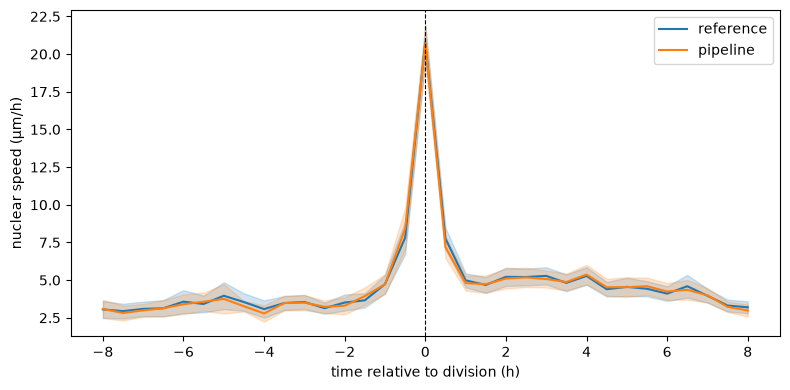

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for s, color in [(steps_ref, "C0"), (steps_pipe, "C1")]:
    w = s[s["rel_frames"].abs() <= WINDOW_FRAMES]
    agg = w.groupby("rel_h")["speed_um_h"].agg(["mean", "sem", "count"])
    ax.plot(agg.index, agg["mean"], color=color, label=s["source"].iloc[0])
    ax.fill_between(agg.index, agg["mean"] - 1.96 * agg["sem"], agg["mean"] + 1.96 * agg["sem"],
                    color=color, alpha=0.2)
ax.axvline(0, ls="--", color="k", lw=0.8)
ax.set_xlabel("time relative to division (h)")
ax.set_ylabel("nuclear speed (µm/h)")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "figures" / f"speed_around_division_seq{SEQ}.png", dpi=150)
plt.show()

## 6. Export for R

In [6]:
cols = ["source", "track", "division_id", "role", "kind", "frame", "rel_frames", "rel_h",
        "dframes", "speed_um_h", "x_um", "y_um"]
steps = pd.concat([steps_ref, steps_pipe], ignore_index=True)[cols]
out = RESULTS / f"steps_speed_seq{SEQ}.csv"
steps.to_csv(out, index=False)
print("saved:", out, "|", len(steps), "rows")

saved: ../results/steps_speed_seq01.csv | 16721 rows


## Results (2026-11-03, sequence 01)
- Reference: 94 divisions, 4,213 steps within ±8 h; pipeline: 86 divisions, 3,719 steps.
- Positions: 8,545 from silver-truth masks, 94 from markers (likely the first frame after each division,
  where both daughter markers still share one silver-truth mask).
- Baseline speed (4–8 h before division) ≈ 2.7 µm/h. No change from −4 to −2 h; 1.7× in the last hour before
  division; 6.2× at the division step (daughter separation, ~8 µm in 30 min); elevated 1.2–1.8× for up to 7 h
  after division; back to baseline at 8 h (R/02_speed_around_mitosis.R).
- Pipeline reproduces the reference: correlation of time effects r = 1.00, same peak, same conclusion in 13/13 bins.
- Caveats: centroid motion includes shape changes (chromatin condensation); 13 comparisons without correction;
  Wald CIs.